# 02 · Scripted expert ("teleoperator") demos

The real dataset was collected by a technician teleoperating WR1. Here a **privileged state
machine** plays that role (`plugsim/expert.py`):

`approach → descend → close → lift → transport → align → insert → hold → release → retreat → home`

* The arm on the plug's side picks it up with a top-down grasp on the boot.
* During transport it re-orients the plug to point into the panel. It then **re-measures the
  plug-in-hand pose** (closed loop) and aligns 20 mm in front of the lit port.
* Insertion uses the compliant controller mode and a bounded push force. A small visual servo runs
  until the tip reaches the chamfer.
* On a jam it **backs off and retries with a spiral search offset** (≤ 3 retries), the way an
  operator wiggles a stuck connector. These recoveries show up in nominal data.

Nominal variability: per-episode speed (×0.85–1.2), approach height, grasp jitter (σ 1.5 mm),
perception noise on the port pose (σ 0.3 mm, 0.3°), plus the scenario randomisation from 00.

In [1]:
# Setup cell, inlined into every notebook by notebooks/build.py.
# Locally: finds the repo. On a Colab runtime (also VS Code connected to Colab), where the code is not
# on the VM: fetches it from (1) PLUGSIM_REPO (git URL, default: the public repo), (2) /content/RobotPluggingSim.zip, or
# (3) MyDrive/RobotPluggingSim (Drive), installs it, and keeps data/ + runs/ on Drive when mounted.
import os, sys, pathlib, subprocess
DEFAULT_REPO = "https://github.com/carlo-scr/RobotPluggingSim.git"
PLUGSIM_REPO = os.environ.get("PLUGSIM_REPO") or DEFAULT_REPO  # Colab: code is cloned from here
USE_DRIVE = os.environ.get("PLUGSIM_DRIVE", "1") == "1"  # set False if drive.mount hangs in your client
IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ
if IN_COLAB:
    os.environ.setdefault("MUJOCO_GL", "egl")
    os.environ.setdefault("PYOPENGL_PLATFORM", "egl")
    CODE = pathlib.Path("/content/RobotPluggingSim")
    DRIVE = pathlib.Path("/content/drive/MyDrive")
    if (CODE / ".git").exists():
        subprocess.run(["git", "-C", str(CODE), "pull", "-q"])  # pick up pushed changes
    if not (CODE / "plugsim").exists():
        if PLUGSIM_REPO:
            subprocess.run(["git", "clone", "-q", PLUGSIM_REPO, str(CODE)], check=True)
        elif pathlib.Path("/content/RobotPluggingSim.zip").exists():
            subprocess.run(["unzip", "-q", "-o", "/content/RobotPluggingSim.zip", "-d", "/content"], check=True)
    if USE_DRIVE and not DRIVE.exists():
        try:
            from google.colab import drive
            drive.mount("/content/drive")
        except Exception as e:  # e.g. not supported by the client; fine with PLUGSIM_REPO or the zip
            print("Drive not mounted:", e)
    if not (CODE / "plugsim").exists():
        if (DRIVE / "RobotPluggingSim").exists():
            subprocess.run(["rsync", "-a", "--exclude", ".venv", "--exclude", "data", "--exclude", "runs", "--exclude", "media",
                            f"{DRIVE}/RobotPluggingSim/", f"{CODE}/"], check=True)
        else:  # last resort: the public repo
            subprocess.run(["git", "clone", "-q", DEFAULT_REPO, str(CODE)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", str(CODE)], check=True)
    if DRIVE.exists():  # persist datasets and checkpoints across sessions / notebooks
        for d in ("data", "runs"):
            tgt = DRIVE / "plugsim_runs" / d
            tgt.mkdir(parents=True, exist_ok=True)
            link = CODE / d
            if not link.is_symlink():
                subprocess.run(["rm", "-rf", str(link)])
                link.symlink_to(tgt)
    else:
        print("WARNING: no Drive: data/ and runs/ live on the VM and are lost when the runtime stops")
    try:
        import torch
        if torch.cuda.is_available():
            os.environ.setdefault("PLUGSIM_SCALE", "a100")
    except ImportError:
        pass
    os.chdir(CODE)
ROOT = pathlib.Path.cwd()
while not (ROOT / "plugsim").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
if sys.platform.startswith("linux") and not os.environ.get("DISPLAY"):
    os.environ.setdefault("MUJOCO_GL", "egl")  # headless GPU nodes
print("ROOT:", ROOT, "| colab:", IN_COLAB, "| scale:", os.environ.get("PLUGSIM_SCALE", "local"))

ROOT: . | colab: False | scale: local


In [2]:
import os, sys, pathlib, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from plugsim.env import PlugEnv
from plugsim.datagen import EpisodeSpec, run_episode
from plugsim.tools import video_html, image_grid

N_EPISODES = 20  # laptop; use thousands via scripts/generate_dataset.py on a GPU node

## Nominal success rate (physics only, no rendering)

In [3]:
env = PlugEnv()
rows, t = [], time.time()
for s in range(N_EPISODES):
    a = run_episode(env, EpisodeSpec(seed=1000 + s), cameras=[], save_states=False)["annotations"]
    rows.append(dict(seed=a["spec"]["seed"], outcome=a["outcome"], mode=a["failure_mode"], arm=a["active_arm"],
                     port=a["target_port"], retries=a["retries"], duration_s=a["duration_s"], latch_s=a["latch_time_s"]))
df = pd.DataFrame(rows)
print(f"{len(df)} episodes in {time.time() - t:.0f}s  ->  success {np.mean(df.outcome == 'success'):.0%}, "
      f"mean duration {df.duration_s.mean():.1f}s, episodes with retries: {(df.retries > 0).sum()}")
df.head(10)

20 episodes in 45s  ->  success 100%, mean duration 8.4s, episodes with retries: 0


,seed,outcome,mode,arm,port,retries,duration_s,latch_s
0,1000,success,none,right,10,0,7.70,5.00
1,1001,success,none,left,39,0,8.20,5.40
2,1002,success,none,left,32,0,8.40,5.65
3,1003,success,none,right,13,0,7.90,5.30
4,1004,success,none,left,35,0,7.45,4.90
5,1005,success,none,left,16,0,9.30,6.20
6,1006,success,none,left,30,0,7.30,4.85
7,1007,success,none,left,7,0,7.55,5.05
8,1008,success,none,left,14,0,8.35,5.50
9,1009,success,none,right,35,0,7.90,5.20


## One episode in detail
Recorded with all cameras, so we can look at it. `run_episode` returns per-step state, action,
and privileged ground truth, which is exactly what gets written to disk in notebook 04.

{'outcome': 'success', 'active_arm': 'right', 'target_port': 13, 'latch_time_s': 5.299999999999989, 'grasp_time_s': 1.4000000000000006, 'retries': 0, 'duration_s': 7.9}


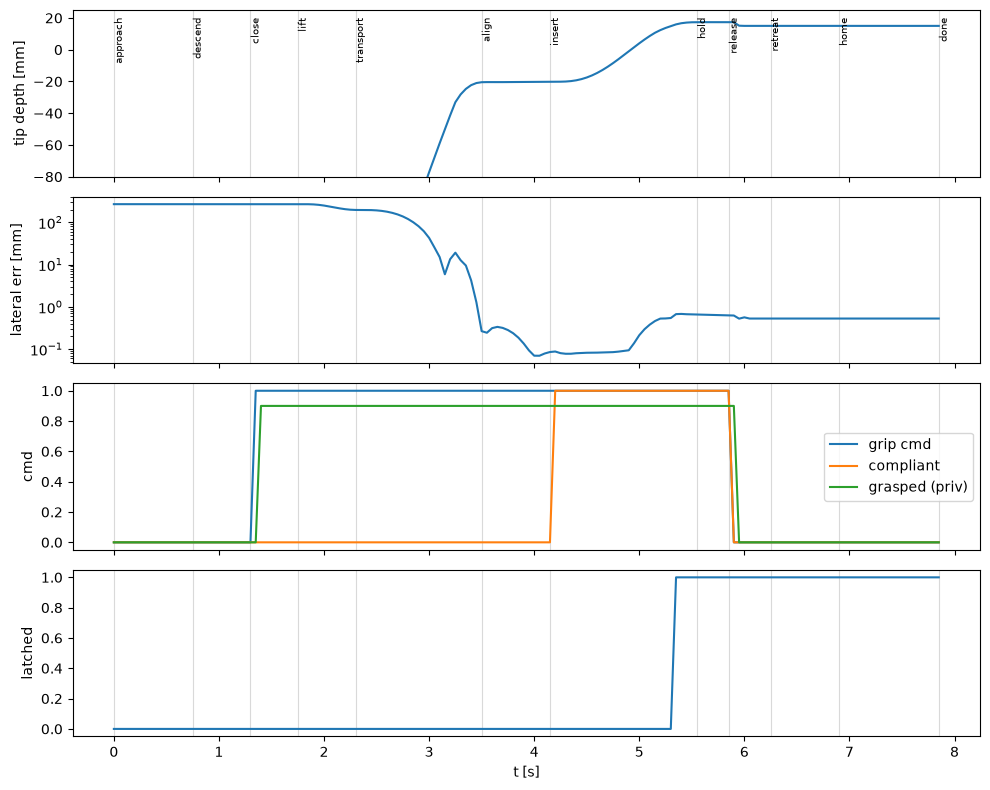

In [4]:
cams = ["right_gripper_front", "right_gripper_rear", "left_gripper_front", "left_gripper_rear", "head_front"]
ep = run_episode(env, EpisodeSpec(seed=1003), cameras=cams)
A, D = ep["annotations"], ep["data"]
print({k: A[k] for k in ("outcome", "active_arm", "target_port", "latch_time_s", "grasp_time_s", "retries", "duration_s")})
t = D["t"]
fig, ax = plt.subplots(4, 1, figsize=(10, 8), sharex=True)
ax[0].plot(t, D["depth"] * 1e3); ax[0].set_ylabel("tip depth [mm]"); ax[0].set_ylim(-80, 25)
ax[1].plot(t, D["lateral"] * 1e3); ax[1].set_ylabel("lateral err [mm]"); ax[1].set_yscale("log")
arm_i = ["right", "left"].index(A["active_arm"])
act = D["action"].reshape(len(t), 2, -1)[:, arm_i]
ax[2].plot(t, act[:, 6], label="grip cmd"); ax[2].plot(t, act[:, 7], label="compliant"); ax[2].plot(t, (D["grasped"] >= 0).astype(float) * 0.9, label="grasped (priv)")
ax[2].legend(loc="right"); ax[2].set_ylabel("cmd")
ax[3].plot(t, D["latched"] >= 0); ax[3].set_ylabel("latched"); ax[3].set_xlabel("t [s]")
for name, te in A["phase_events"]:
    for a_ in ax:
        a_.axvline(te, color="0.85", lw=0.8, zorder=0)
    ax[0].text(te, 20, name, fontsize=7, rotation=90, va="top")
plt.tight_layout(); plt.show()

In [5]:
side = A["active_arm"]
frames = [np.concatenate([np.concatenate([ep["frames"][f"{side}_gripper_front"][i], ep["frames"][f"{side}_gripper_rear"][i]], 1),
                          np.concatenate([ep["frames"]["head_front"][i], np.zeros_like(ep["frames"]["head_front"][i])], 1)], 0)
          for i in range(len(t))]
video_html(frames, fps=20, width=760)

## Episode statistics
Recorded TCP trajectories of the active arm in a few episodes (top view), and the action
magnitudes the policy will have to learn.

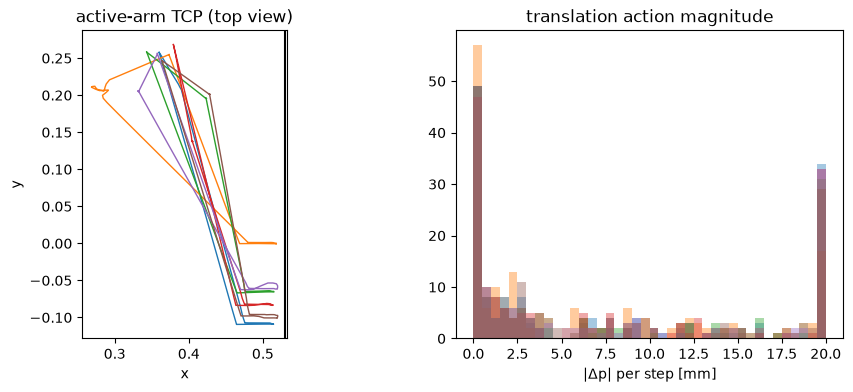

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for s in range(6):
    e = run_episode(env, EpisodeSpec(seed=1100 + s), cameras=[], save_states=False)
    st = e["data"]["state"]; i = ["right", "left"].index(e["annotations"]["active_arm"])
    tcp = st[:, 22 * i + 14 : 22 * i + 17]
    ax[0].plot(tcp[:, 0], tcp[:, 1], lw=1)
    a = e["data"]["action"].reshape(len(st), 2, -1)[:, i]
    ax[1].hist(np.linalg.norm(a[:, :3], axis=1) * 1e3, bins=40, alpha=.4)
ax[0].axvline(env.cfg.rack.face_x, color="k"); ax[0].set_aspect("equal"); ax[0].set_title("active-arm TCP (top view)"); ax[0].set_xlabel("x"); ax[0].set_ylabel("y")
ax[1].set_xlabel("|Δp| per step [mm]"); ax[1].set_title("translation action magnitude"); plt.show()